# Assignment 2: Convolution


*This notebook organization:*

| Section | Question | Training sample | Validation | Test |
|---|---|---:|---:|---:|
| Question 1 | Train from scratch, small sample | 1,000 (500 cats + 500 dogs) | 500 | 500 |
| Question 2 | Train from scratch, increase the sample | 1,500 (750 + 750) | 500 | 500 |
| Question 3 | Train from scratch, find the ideal size | 2,000 (1,000 + 1,000) | 500 | 500 |
| Question 4 | Repeat Questions 1–3 with a pretrained network | 1,000 / 1,500 / 2,000 | 500 | 500 |

*Design notes:*
- The three training sets are **nested** — the 1,000 set is inside the 1,500 set, which is inside the 2,000 set — so training size is the only thing that changes between Questions 1–3.
- Validation and test sets **never change**, so every question's performance is directly comparable.

###Load required packages

In [3]:
import zipfile
import random
import shutil
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


###Preparation 1 — Load data

In [4]:
# unzip cell
zip_path = Path("/content/cats_vs_dogs_small.zip")
extract_dir = Path("/content/cats_vs_dogs_extracted")

if not extract_dir.exists():
    zipfile.ZipFile(zip_path).extractall(extract_dir)


In [5]:
# Find the dataset folder
base_dir = extract_dir / "cats_vs_dogs_small"
if not base_dir.exists():
    base_dir = extract_dir

print("base_dir =", base_dir)

for class_dir in sorted(base_dir.rglob("*")):
    if class_dir.is_dir() and class_dir.name in ("cats", "dogs"):
        print(class_dir.parent.name, class_dir.name, len(list(class_dir.iterdir())))


base_dir = /content/cats_vs_dogs_extracted/cats_vs_dogs_small
test cats 500
test dogs 500
train cats 1000
train dogs 1000
validation cats 500
validation dogs 500


###Preparation 2 — Build the samples



In [7]:
train = base_dir / "train"
validation = base_dir / "validation"
test = base_dir / "test"

work_dir = Path("/content/a2_subsets")
if work_dir.exists():
    shutil.rmtree(work_dir)

def copy_subset(source, dest, n_per_class, seed=123):
    for class_name in ["cats", "dogs"]:
        files = sorted((source / class_name).iterdir())
        random.Random(seed).shuffle(files)
        target = dest / class_name
        target.mkdir(parents=True, exist_ok=True)
        for f in files[:n_per_class]:
            shutil.copy(f, target / f.name)

copy_subset(validation, work_dir / "validation", 250)
copy_subset(test, work_dir / "test", 250)

for total, per_class in {1000: 500, 1500: 750, 2000: 1000}.items():
    copy_subset(train, work_dir / f"train_{total}", per_class)


### Preparation 3 — Utilities

In [8]:
image_size = (150, 150)
batch_size = 32
results = []

def load(directory, shuffle=False, seed=None):
    return keras.utils.image_dataset_from_directory(
        directory, image_size=image_size, batch_size=batch_size,
        label_mode="binary", shuffle=shuffle, seed=seed)

def make_datasets(train_dir):
    train_ds = load(train_dir, shuffle=True, seed=123)
    val_ds = load(work_dir / "validation")
    test_ds = load(work_dir / "test")
    return train_ds, val_ds, test_ds

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.2),
])

def plot_history(history, title):
    epochs = range(1, len(history.history["accuracy"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(epochs, history.history["accuracy"], "bo", label="Training accuracy")
    ax1.plot(epochs, history.history["val_accuracy"], "b", label="Validation accuracy")
    ax1.set_title(title + " — accuracy")
    ax1.legend()
    ax2.plot(epochs, history.history["loss"], "bo", label="Training loss")
    ax2.plot(epochs, history.history["val_loss"], "b", label="Validation loss")
    ax2.set_title(title + " — loss")
    ax2.legend()
    plt.show()

def record_result(question, approach, train_size, history, test_acc):
    best_val_acc = max(history.history["val_accuracy"])
    final_val_acc = history.history["val_accuracy"][-1]
    print(question, "|", approach, "| train =", train_size,
          "| best_val_acc =", round(best_val_acc, 4),
          "| final_val_acc =", round(final_val_acc, 4),
          "| test_acc =", round(test_acc, 4))
    results.append({
        "Question": question,
        "Approach": approach,
        "Training size": train_size,
        "Best validation accuracy": round(best_val_acc, 4),
        "Final validation accuracy": round(final_val_acc, 4),
        "Test accuracy": round(test_acc, 4),
    })


###Question 1 — From scratch, 1000

Found 1000 files belonging to 2 classes.
Found 500 files belonging to 2 classes.
Found 500 files belonging to 2 classes.


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 68ms/step - accuracy: 0.4930 - loss: 0.6961 - val_accuracy: 0.5320 - val_loss: 0.6914
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.5230 - loss: 0.6923 - val_accuracy: 0.5520 - val_loss: 0.6892
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 53ms/step - accuracy: 0.5350 - loss: 0.6914 - val_accuracy: 0.5760 - val_loss: 0.6864
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - accuracy: 0.5580 - loss: 0.6872 - val_accuracy: 0.5380 - val_loss: 0.6841
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.5640 - loss: 0.6842 - val_accuracy: 0.5100 - val_loss: 0.6989
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.5610 - loss: 0.6803 - val_accuracy: 0.5780 - val_loss: 0.6772
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 47ms/step - accuracy: 0.5820 - loss: 0.6735 - val_accuracy: 0.5600 - val_loss: 0.6763
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 47ms/step - accuracy: 0.5950 - loss: 0.6696 - val_accuracy: 0.5980 - v

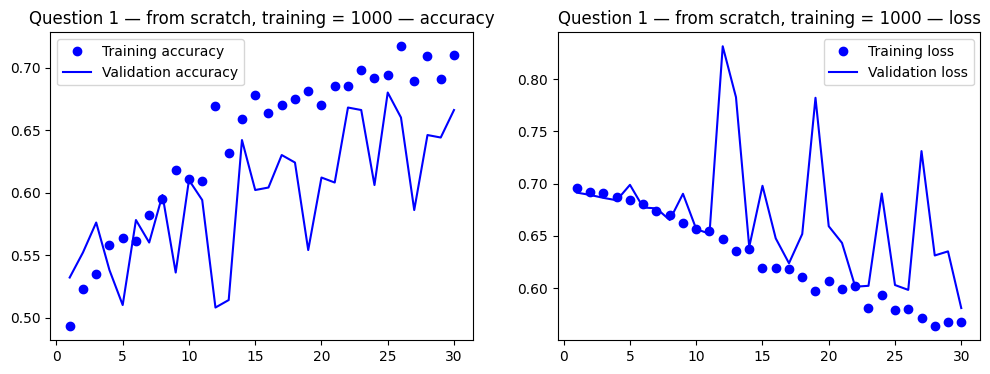

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.6780 - loss: 0.5938
Question 1 | From scratch | train = 1000 | best_val_acc = 0.68 | final_val_acc = 0.666 | test_acc = 0.678


In [9]:

train_ds, val_ds, test_ds = make_datasets(work_dir / "train_1000")

inputs = keras.Input(shape=(150, 150, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1.0 / 255)(x)
x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(512, activation="relu")(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
              loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

history = model.fit(train_ds, epochs=30, validation_data=val_ds)
plot_history(history, "Question 1 — from scratch, training = 1000")

test_loss, test_acc = model.evaluate(test_ds)
record_result("Question 1", "From scratch", 1000, history, test_acc)


### Question 2 — From scratch, 1500



Found 1500 files belonging to 2 classes.
Found 500 files belonging to 2 classes.
Found 500 files belonging to 2 classes.


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 5s 65ms/step - accuracy: 0.5027 - loss: 0.6946 - val_accuracy: 0.5000 - val_loss: 0.6911
Epoch 2/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.5253 - loss: 0.6908 - val_accuracy: 0.5020 - val_loss: 0.6897
Epoch 3/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step - accuracy: 0.5307 - loss: 0.6906 - val_accuracy: 0.5140 - val_loss: 0.6865
Epoch 4/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.5400 - loss: 0.6869 - val_accuracy: 0.5040 - val_loss: 0.6894
Epoch 5/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.5667 - loss: 0.6816 - val_accuracy: 0.5760 - val_loss: 0.6750
Epoch 6/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.5880 - loss: 0.6740 - val_accuracy: 0.6120 - val_loss: 0.6642
Epoch 7/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.5933 - loss: 0.6642 - val_accuracy: 0.6000 - val_loss: 0.6617
Epoch 8/30
47/47 ━━━━━━━━━━━━━━━━━━━━ 2s 45ms/step - accuracy: 0.6013 - loss: 0.6605 - val_accuracy: 0.6060 - v

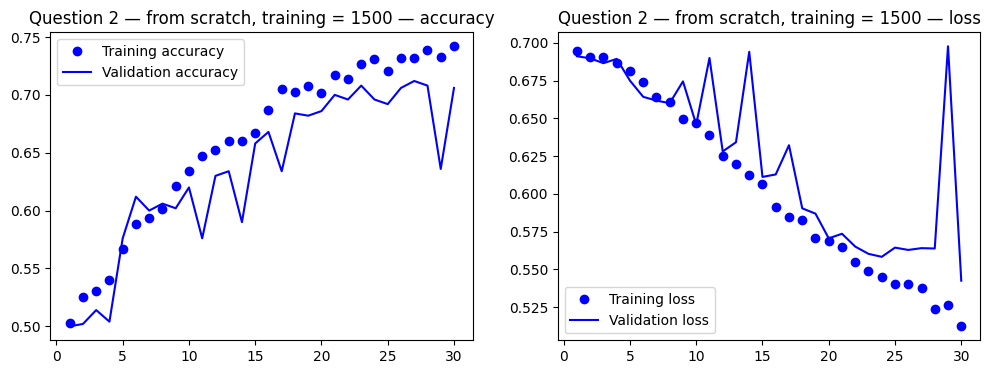

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - accuracy: 0.6860 - loss: 0.5871
Question 2 | From scratch | train = 1500 | best_val_acc = 0.712 | final_val_acc = 0.706 | test_acc = 0.686


In [10]:
train_ds, val_ds, test_ds = make_datasets(work_dir / "train_1500")

inputs = keras.Input(shape=(150, 150, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1.0 / 255)(x)
x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(512, activation="relu")(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
              loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

history = model.fit(train_ds, epochs=30, validation_data=val_ds)
plot_history(history, "Question 2 — from scratch, training = 1500")

test_loss, test_acc = model.evaluate(test_ds)
record_result("Question 2", "From scratch", 1500, history, test_acc)


### Question 3  — From scratch, 1500

Found 2000 files belonging to 2 classes.
Found 500 files belonging to 2 classes.
Found 500 files belonging to 2 classes.


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_2 (Rescaling)         │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 15, 15, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │     3,211,776 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,453,121 (13.17 MB)

 Trainable params: 3,453,121 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 52ms/step - accuracy: 0.5075 - loss: 0.6950 - val_accuracy: 0.5340 - val_loss: 0.6903
Epoch 2/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 41ms/step - accuracy: 0.5365 - loss: 0.6903 - val_accuracy: 0.5580 - val_loss: 0.6850
Epoch 3/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 5s 43ms/step - accuracy: 0.5380 - loss: 0.6880 - val_accuracy: 0.5920 - val_loss: 0.6778
Epoch 4/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.5605 - loss: 0.6819 - val_accuracy: 0.5820 - val_loss: 0.6668
Epoch 5/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 44ms/step - accuracy: 0.5860 - loss: 0.6709 - val_accuracy: 0.5860 - val_loss: 0.6588
Epoch 6/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 6s 52ms/step - accuracy: 0.5895 - loss: 0.6622 - val_accuracy: 0.6100 - val_loss: 0.6505
Epoch 7/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.6240 - loss: 0.6535 - val_accuracy: 0.5680 - val_loss: 0.7030
Epoch 8/30
63/63 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.6315 - loss: 0.6403 - val_accuracy: 0.6140 - v

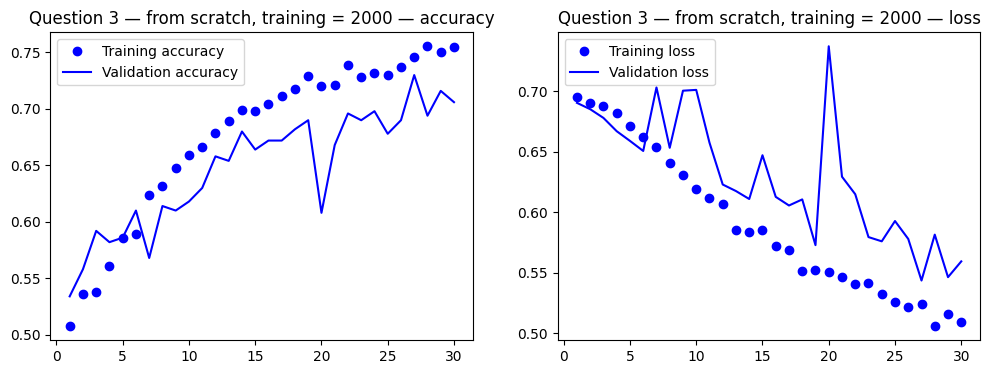

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.6960 - loss: 0.6243
Question 3 | From scratch | train = 2000 | best_val_acc = 0.73 | final_val_acc = 0.706 | test_acc = 0.696


In [11]:
# Question 3 — From scratch, 2000
train_ds, val_ds, test_ds = make_datasets(work_dir / "train_2000")

inputs = keras.Input(shape=(150, 150, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1.0 / 255)(x)
x = layers.Conv2D(32, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(64, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Conv2D(128, 3, activation="relu")(x)
x = layers.MaxPooling2D(2)(x)
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(512, activation="relu")(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=1e-4),
              loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

history = model.fit(train_ds, epochs=30, validation_data=val_ds)
plot_history(history, "Question 3 — from scratch, training = 2000")

test_loss, test_acc = model.evaluate(test_ds)
record_result("Question 3", "From scratch", 2000, history, test_acc)


### Question 4 — splits into three: Pretrained base

In [12]:
conv_base = keras.applications.VGG16(
    weights="imagenet", include_top=False, input_shape=(150, 150, 3))
conv_base.summary()
conv_base.trainable = False

def extract_features(directory, sample_count):
    dataset = keras.utils.image_dataset_from_directory(
        directory, image_size=image_size, batch_size=batch_size,
        label_mode="binary", shuffle=False)
    features, labels, seen = [], [], 0
    for images, batch_labels in dataset:
        features.append(conv_base.predict(images / 255.0, verbose=0))
        labels.append(batch_labels.numpy())
        seen += images.shape[0]
        if seen >= sample_count:
            break
    features = np.concatenate(features)[:sample_count]
    labels = np.concatenate(labels)[:sample_count]
    return features.reshape(sample_count, 4 * 4 * 512), labels

val_features, val_labels = extract_features(work_dir / "validation", 500)
test_features, test_labels = extract_features(work_dir / "test", 500)
print("Validation features:", val_features.shape)
print("Test features:", test_features.shape)


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

Found 500 files belonging to 2 classes.
Found 500 files belonging to 2 classes.
Validation features: (500, 8192)
Test features: (500, 8192)


### Question 4.1 — pretrained: 1,000

Found 1000 files belonging to 2 classes.
Training features: (1000, 8192)


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,097,665 (8.00 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.6370 - loss: 0.6486 - val_accuracy: 0.8080 - val_loss: 0.5131
Epoch 2/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7680 - loss: 0.5039 - val_accuracy: 0.8340 - val_loss: 0.4482
Epoch 3/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8140 - loss: 0.4178 - val_accuracy: 0.8740 - val_loss: 0.3914
Epoch 4/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8420 - loss: 0.3726 - val_accuracy: 0.8700 - val_loss: 0.3625
Epoch 5/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8800 - loss: 0.3260 - val_accuracy: 0.8760 - val_loss: 0.3391
Epoch 6/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8760 - loss: 0.3103 - val_accuracy: 0.8880 - val_loss: 0.3223
Epoch 7/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8920 - loss: 0.2753 - val_accuracy: 0.8960 - val_loss: 0.3075
Epoch 8/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8970 - loss: 0.2734 - val_accuracy: 0.8840 - val_loss

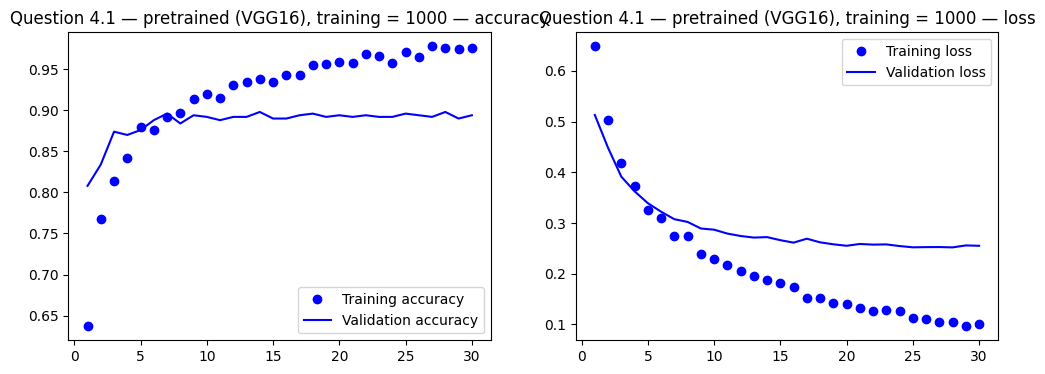

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8840 - loss: 0.2756
Question 4.1 | Pretrained (VGG16) | train = 1000 | best_val_acc = 0.898 | final_val_acc = 0.894 | test_acc = 0.884


In [13]:
train_features, train_labels = extract_features(work_dir / "train_1000", 1000)
print("Training features:", train_features.shape)

inputs = keras.Input(shape=(4 * 4 * 512,))
x = layers.Dense(256, activation="relu")(inputs)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=2e-5),
              loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

history = model.fit(train_features, train_labels, epochs=30, batch_size=20,
                    validation_data=(val_features, val_labels))
plot_history(history, "Question 4.1 — pretrained (VGG16), training = 1000")

test_loss, test_acc = model.evaluate(test_features, test_labels)
record_result("Question 4.1", "Pretrained (VGG16)", 1000, history, test_acc)


### Question 4.2 — pretrained: 1500


Found 1500 files belonging to 2 classes.
Training features: (1500, 8192)


Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,097,665 (8.00 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6287 - loss: 0.6504 - val_accuracy: 0.8020 - val_loss: 0.4865
Epoch 2/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7840 - loss: 0.4618 - val_accuracy: 0.8360 - val_loss: 0.4030
Epoch 3/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8287 - loss: 0.3899 - val_accuracy: 0.8540 - val_loss: 0.3583
Epoch 4/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8533 - loss: 0.3429 - val_accuracy: 0.8500 - val_loss: 0.3492
Epoch 5/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8760 - loss: 0.3053 - val_accuracy: 0.8800 - val_loss: 0.3118
Epoch 6/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8873 - loss: 0.2753 - val_accuracy: 0.8820 - val_loss: 0.2985
Epoch 7/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8980 - loss: 0.2580 - val_accuracy: 0.8920 - val_loss: 0.2879
Epoch 8/30
75/75 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8993 - loss: 0.2507 - val_accuracy: 0.8900 - val_loss:

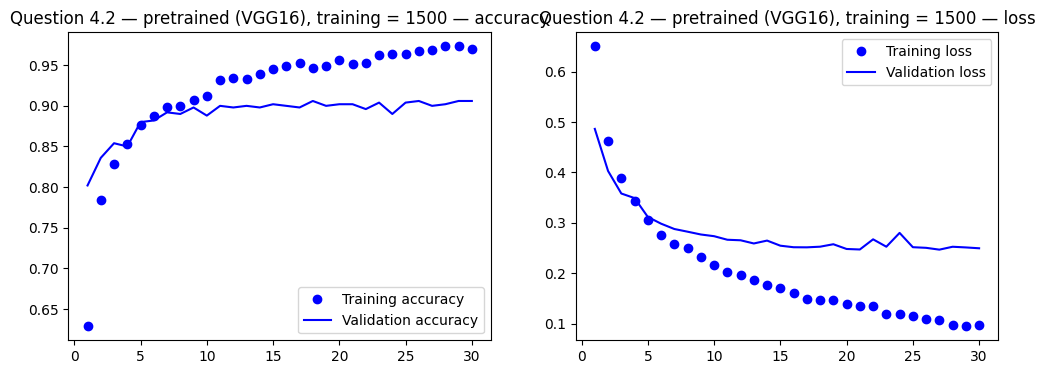

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.8840 - loss: 0.2572
Question 4.2 | Pretrained (VGG16) | train = 1500 | best_val_acc = 0.906 | final_val_acc = 0.906 | test_acc = 0.884


In [14]:
train_features, train_labels = extract_features(work_dir / "train_1500", 1500)
print("Training features:", train_features.shape)

inputs = keras.Input(shape=(4 * 4 * 512,))
x = layers.Dense(256, activation="relu")(inputs)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=2e-5),
              loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

history = model.fit(train_features, train_labels, epochs=30, batch_size=20,
                    validation_data=(val_features, val_labels))
plot_history(history, "Question 4.2 — pretrained (VGG16), training = 1500")

test_loss, test_acc = model.evaluate(test_features, test_labels)
record_result("Question 4.2", "Pretrained (VGG16)", 1500, history, test_acc)


### Question 4.3 — pretrained: 2,000

Found 2000 files belonging to 2 classes.
Training features: (2000, 8192)


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,097,665 (8.00 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6855 - loss: 0.5859 - val_accuracy: 0.8380 - val_loss: 0.4448
Epoch 2/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8285 - loss: 0.4123 - val_accuracy: 0.8680 - val_loss: 0.3596
Epoch 3/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8570 - loss: 0.3411 - val_accuracy: 0.8720 - val_loss: 0.3304
Epoch 4/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8730 - loss: 0.3022 - val_accuracy: 0.8820 - val_loss: 0.2989
Epoch 5/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8965 - loss: 0.2756 - val_accuracy: 0.8820 - val_loss: 0.2938
Epoch 6/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8945 - loss: 0.2589 - val_accuracy: 0.8940 - val_loss: 0.2817
Epoch 7/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9050 - loss: 0.2432 - val_accuracy: 0.9000 - val_loss: 0.2688
Epoch 8/30
100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9140 - loss: 0.2263 - val_accuracy: 0.

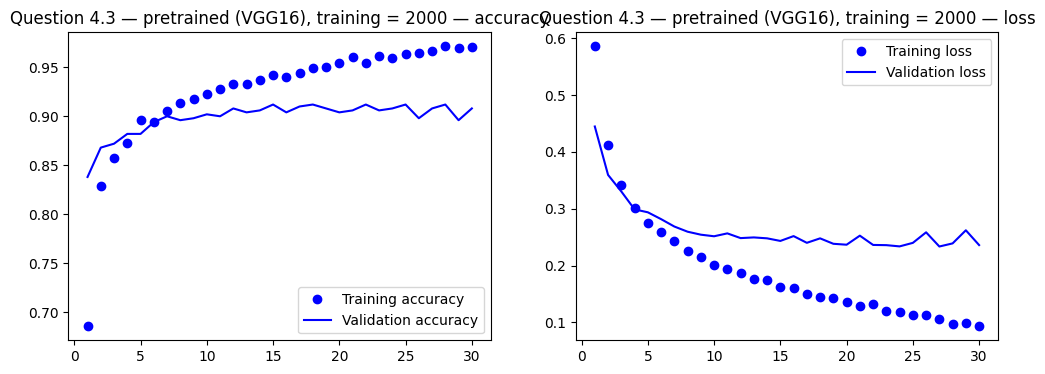

16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.8920 - loss: 0.2478
Question 4.3 | Pretrained (VGG16) | train = 2000 | best_val_acc = 0.912 | final_val_acc = 0.908 | test_acc = 0.892


In [15]:
train_features, train_labels = extract_features(work_dir / "train_2000", 2000)
print("Training features:", train_features.shape)

inputs = keras.Input(shape=(4 * 4 * 512,))
x = layers.Dense(256, activation="relu")(inputs)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = keras.Model(inputs, outputs)
model.compile(optimizer=keras.optimizers.RMSprop(learning_rate=2e-5),
              loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

history = model.fit(train_features, train_labels, epochs=30, batch_size=20,
                    validation_data=(val_features, val_labels))
plot_history(history, "Question 4.3 — pretrained (VGG16), training = 2000")

test_loss, test_acc = model.evaluate(test_features, test_labels)
record_result("Question 4.3", "Pretrained (VGG16)", 2000, history, test_acc)


### Summary — Results table and graph

       Question            Approach  Training size  Best validation accuracy  \
0    Question 1        From scratch           1000                     0.680   
1    Question 2        From scratch           1500                     0.712   
2    Question 3        From scratch           2000                     0.730   
3  Question 4.1  Pretrained (VGG16)           1000                     0.898   
4  Question 4.2  Pretrained (VGG16)           1500                     0.906   
5  Question 4.3  Pretrained (VGG16)           2000                     0.912   

   Final validation accuracy  Test accuracy  
0                      0.666          0.678  
1                      0.706          0.686  
2                      0.706          0.696  
3                      0.894          0.884  
4                      0.906          0.884  
5                      0.908          0.892  


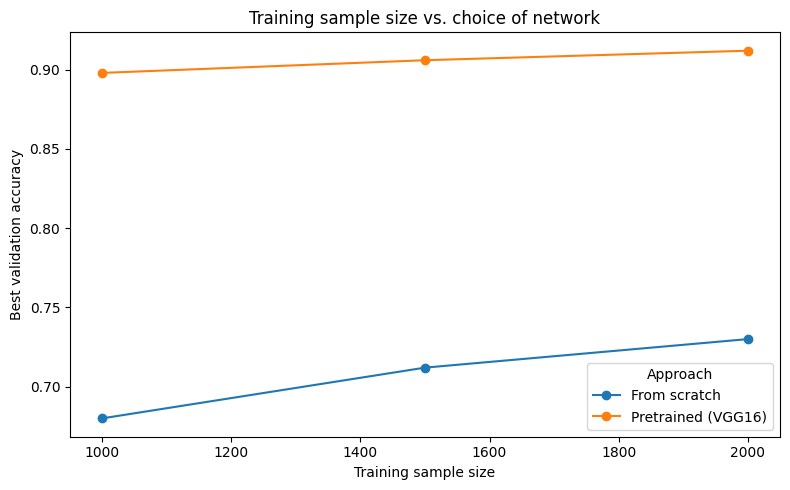

In [16]:
results_table = pd.DataFrame(results)
print(results_table)
results_table.to_csv("/content/assignment2_results.csv", index=False)

pivot = results_table.pivot(index="Training size", columns="Approach",
                            values="Best validation accuracy")
ax = pivot.plot(marker="o", figsize=(8, 5))
ax.set_xlabel("Training sample size")
ax.set_ylabel("Best validation accuracy")
ax.set_title("Training sample size vs. choice of network")
plt.tight_layout()
plt.savefig("/content/assignment2_summary_graph.png", dpi=150)
plt.show()
